In [2]:
from __future__ import annotations

import itertools
import warnings
from collections import defaultdict

import mne
import pathlib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scripts.dataset_manager import write_raw_dataset, read_raw_dataset

from math import ceil
from scipy import stats
from pyprep import NoisyChannels
from autoreject import AutoReject

mne.set_log_level("WARNING")

from scripts import paper_style  # two-column paper style for every figure (sizes/font in scripts/paper_style.py)
from scripts.paper_style import COL_W, TEXT_W, enforce_font_sizes, subject_id, session_label
paper_style.apply(seaborn_style='whitegrid')

In [2]:
raw_dataset = None
RAW_DATASET_NAME = pathlib.Path('data/raw_dataset')
EPOCH_DATASET_NAME = pathlib.Path('data/epoch_dataset')
EPOCH_FILTERED_DATASET_NAME = pathlib.Path('data/epoch_dataset_filtered')
FIG_DIR = pathlib.Path('out/figs')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# AutoReject decides on a copy with this extra highpass; the saved epochs keep the dataset's 0.3Hz highpass
AR_DECISION_L_FREQ = 1.0

EPOCH_TYPE = 'PinchLog'
EPOCH_TYPE_NOPINCH = 'NoPinchLog'
META_COL = 'PinchType'
CLASSES = ['PINCH', 'GAZE', 'PINCH_WIZARD_OF_OZ', 'PINCH_IGNORED']
PALETTE = dict(zip(CLASSES, sns.color_palette("Set2", len(CLASSES))))

In [3]:
raw = read_raw_dataset(RAW_DATASET_NAME)
epochs_dict = read_raw_dataset(EPOCH_DATASET_NAME)

In [4]:
# region helper functions
def iter_sessions(d):
    """Yield (subject, session, value) over the nested dict, sorted."""
    for sub in sorted(d):
        for ses in sorted(d[sub]):
            yield sub, ses, d[sub][ses]


def get_pinchlog(epochs: mne.Epochs) -> mne.Epochs:
    """Return only the PinchLog epochs.

    Works whether 'PinchLog' is an event_id key, a prefix of hierarchical
    event ids ('PinchLog/pinch'), or a metadata column value.
    """
    if epochs.metadata is not None and "EpochType" in epochs.metadata:
        return epochs[f'EpochType == "{EPOCH_TYPE}"']
    keys = [k for k in epochs.event_id if EPOCH_TYPE in k]
    if not keys:
        raise KeyError(f"No {EPOCH_TYPE} events in {list(epochs.event_id)}")
    return epochs[keys]


def by_class(epochs: mne.Epochs, cls: str) -> mne.Epochs:
    """Select one PinchType level via the metadata query interface."""
    return epochs[f'{META_COL} == "{cls}"']


def stack_metadata(epochs_dict) -> pd.DataFrame:
    """Concatenate all PinchLog metadata into one long dataframe with keys."""
    rows = []
    for sub, ses, ep in iter_sessions(epochs_dict):
        ep = get_pinchlog(ep)
        md = ep.metadata.copy().reset_index(drop=True)
        md["subject"], md["session"] = sub, ses
        md["epoch_idx"] = np.arange(len(md))
        md["onset_s"] = ep.events[:, 0] / ep.info["sfreq"]
        rows.append(md)
    return pd.concat(rows, ignore_index=True)


def common_channels(epochs_dict) -> list[str]:
    """Intersection of channel names across every session (order preserved)."""
    sets = [set(ep.ch_names) for _, _, ep in iter_sessions(epochs_dict)]
    keep = set.intersection(*sets)
    first = next(iter_sessions(epochs_dict))[2]
    return [ch for ch in first.ch_names if ch in keep]

def merge_epochs_dict(epochs_dict):
    """Merges the dict of epochs into a single epoch object, preserving subject and session identification in the metadata."""
    all_epochs = []

    for subj, sessions in epochs_dict.items():
        for sess, ep in sessions.items():
            ep = ep.copy()

            # build/extend metadata with subject + session
            n = len(ep)
            extra = pd.DataFrame(
                {"subject": [subj] * n, "session": [sess] * n},
                index=ep.metadata.index if ep.metadata is not None else range(n),
            )

            if ep.metadata is None:
                ep.metadata = extra
            else:
                # avoid clobbering if these columns already exist
                meta = ep.metadata.copy()
                meta["subject"] = subj
                meta["session"] = sess
                ep.metadata = meta

            all_epochs.append(ep)

    merged = mne.concatenate_epochs(all_epochs)
    return merged

epochs = merge_epochs_dict(epochs_dict)

# endregion

C:\Users\nicol\AppData\Local\Temp\ipykernel_40900\3372723314.py:74: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  merged = mne.concatenate_epochs(all_epochs)


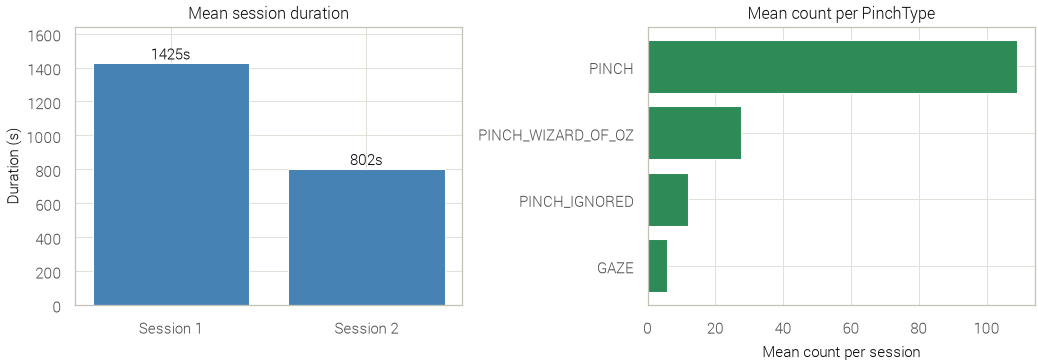

In [6]:
import matplotlib.pyplot as plt

def plot_eeg_stats(stats: dict, data: dict):
    fig, axes = plt.subplots(1, 2, figsize=(TEXT_W, 2.6))

    # --- 1. Mean session duration ---
    ax = axes[0]
    dur = stats['mean_session_duration']
    ax.bar(dur['session'].map(session_label), dur['mean_duration_s'], color='steelblue')
    ax.set_title('Mean session duration')
    ax.set_ylabel('Duration (s)')
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.set_ylim(top=dur['mean_duration_s'].max() * 1.15)  # room for the value labels
    for i, v in enumerate(dur['mean_duration_s']):
        ax.text(i, v, f'{v:.0f}s', ha='center', va='bottom')

    # --- 2. Mean PinchType counts ---
    ax = axes[1]
    pt = stats['mean_pinch_type_counts'].sort_values('mean_count', ascending=True)
    if not pt.empty:
        ax.barh(pt['PinchType'].astype(str), pt['mean_count'], color='seagreen')
        ax.set_title('Mean count per PinchType')
        ax.set_xlabel('Mean count per session')
        ax.xaxis.grid(True)
        ax.set_axisbelow(True)
    else:
        ax.text(0.5, 0.5, 'No PinchType data', ha='center', va='center')
        ax.set_title('Mean count per PinchType')

    plt.tight_layout()
    plt.savefig(FIG_DIR / 'eeg_stats_overview.pdf')
    plt.show()


def eeg_dataset_stats(data: dict) -> dict:
    """
    data: {subject: {session: {'eeg': mne.Raw, 'markers': pd.DataFrame, ...}}}
    Returns a dict of DataFrames, one per requested stat.
    """
    duration_rows = []
    pinch_type_rows = []

    for subject, sessions in data.items():
        for session, d in sessions.items():
            eeg = d['eeg']
            markers = d['markers']

            # --- session duration ---
            duration_s = eeg.times[-1] - eeg.times[0]
            duration_rows.append({
                'subject': subject, 'session': session, 'duration_s': duration_s
            })

            # --- PinchType counts, restricted to EventType == 'PinchLog' ---
            pinch_events = markers[markers['EventType'] == 'PinchLog']
            pinch_counts = pinch_events['PinchType'].value_counts()
            for pinch_type, count in pinch_counts.items():
                pinch_type_rows.append({
                    'subject': subject, 'session': session,
                    'PinchType': pinch_type, 'count': count
                })

    duration_df = pd.DataFrame(duration_rows)
    pinch_type_df = pd.DataFrame(pinch_type_rows)

    # --- aggregations ---

    # mean session duration, per session label (session_1, session_2, ...)
    mean_duration = (
        duration_df.groupby('session')['duration_s']
        .mean()
        .rename('mean_duration_s')
        .reset_index()
    )

    # mean number of entries per PinchType value (same zero-fill logic)
    all_sessions = duration_df[['subject', 'session']].drop_duplicates()
    if not pinch_type_df.empty:
        pinch_full = (
            all_sessions.merge(pinch_type_df[['PinchType']].drop_duplicates(), how='cross')
            .merge(pinch_type_df, on=['subject', 'session', 'PinchType'], how='left')
            .fillna({'count': 0})
        )
        mean_pinch_counts = (
            pinch_full.groupby('PinchType')['count']
            .mean()
            .rename('mean_count')
            .reset_index()
        )
    else:
        mean_pinch_counts = pd.DataFrame(columns=['PinchType', 'mean_count'])

    return {
        'mean_session_duration': mean_duration,
        'mean_pinch_type_counts': mean_pinch_counts,
    }

s = eeg_dataset_stats(raw)
plot_eeg_stats(s, raw)

Short sanity check to make sure that events are distributed over the full session. This makes sure that classifications will not be trivial when classifiers learn electrode drift, fatigue due to session duration.

The diagram shows a pretty good distribution over the entire experiment with an exception to the end of the experiment, as there is a control experiment there.

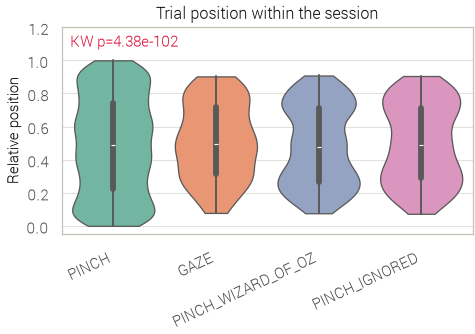

In [7]:
def plot_design_confounds(epochs_dict, extra_cols=("ReactionTime",)):
    md = stack_metadata(epochs_dict)
    md["rel_position"] = md.groupby(["subject", "session"])["epoch_idx"] \
                           .transform(lambda s: s / max(s.max(), 1))

    col = "rel_position"
    fig, ax = plt.subplots(1, 1, figsize=(COL_W, 2.4))
    sns.violinplot(data=md, x=META_COL, y=col, order=CLASSES,
                   hue=META_COL, hue_order=CLASSES, palette=PALETTE,
                   legend=False, cut=0, ax=ax)
    ax.set_title("Trial position within the session")
    ax.set_ylabel("Relative position")
    ax.set_xlabel("")
    ax.set_ylim(top=1.2)  # room for the test result above the violins
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")

    groups = [g[col].dropna().values for _, g in md.groupby(META_COL)]
    if all(len(g) > 1 for g in groups):
        H, p = stats.kruskal(*groups)
        ax.text(.02, .98, f"KW p={p:.3g}", transform=ax.transAxes,
                va="top",
                color="crimson" if p < .01 else "gray")
    fig.tight_layout()
    return fig, md

_ = plot_design_confounds(epochs_dict)

# Signal and channel quality

At first glance, not all measurements were of good quality.

Observed issues:

- Missing alpha-bump at 8-12Hz for some measurements
- Overall high PSD for some measurements, indicating high noise/drift.

C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length  = 495, using nperseg = 495
  return _func(*args, **kwargs)
C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length  = 102, using nperseg = 102
  return _func(*args, **kwargs)
C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length  = 189, using nperseg = 189
  return _func(*args, **kwargs)
C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length  = 169, using nperseg = 169
  return _func(*args, **kwargs)
C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length 

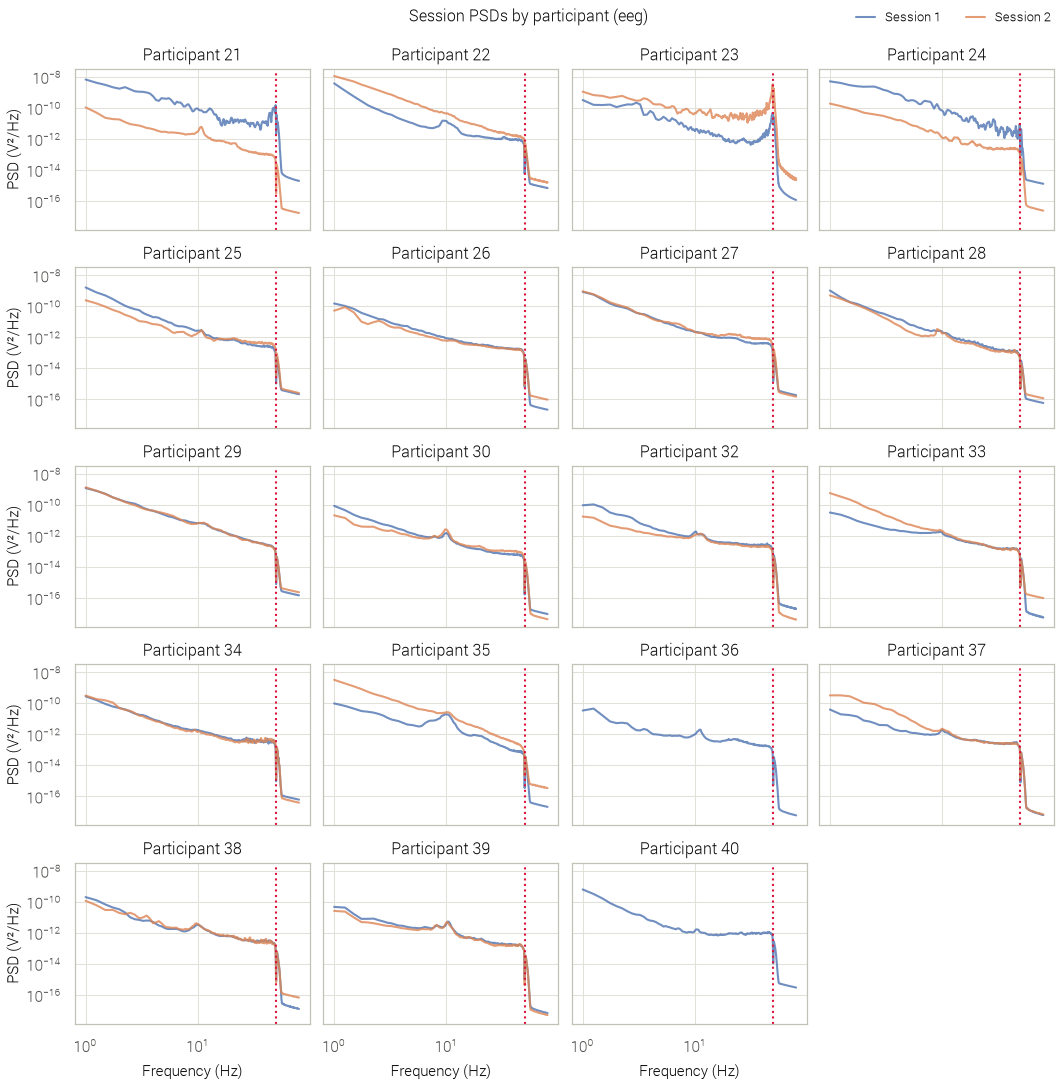

In [8]:
def plot_session_psds_by_subject(raws_dict, fmax=80, picks="eeg", figsize=None,
                                  eeg_field_name="eeg_raw", n_cols=4):
    # First pass: compute PSDs, capping n_fft to each recording's actual length
    # so we never ask Welch's method for a longer segment than exists.
    records = []
    for sub, ses, raw_dict in iter_sessions(raws_dict):
        raw_eeg = raw_dict[eeg_field_name]
        psd = raw_eeg.compute_psd(fmin=1, fmax=fmax, picks=picks, n_fft=int(4 * raw_eeg.info["sfreq"]))
        f = psd.freqs
        m = psd.get_data().mean(axis=0)
        records.append((sub, ses, f, m))

    subjects = sorted(set(r[0] for r in records))
    n_cols = min(n_cols, len(subjects))
    n_rows = ceil(len(subjects) / n_cols)
    if figsize is None:
        figsize = (TEXT_W, 1.35 * n_rows + 0.5)

    # sharex/sharey guarantees every panel spans the exact same axis range
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize,
                              sharex=True, sharey=True, squeeze=False,
                              layout="constrained")
    axes_flat = axes.ravel()
    session_lines = {}  # one shared legend instead of one per panel

    for ax, sub in zip(axes_flat, subjects):
        for s, ses, f, m in records:
            if s != sub:
                continue
            line, = ax.loglog(f, m, lw=1, alpha=.8, label=session_label(ses))
            session_lines.setdefault(session_label(ses), line)
        for hz in (50, 100):
            if hz < fmax:
                ax.axvline(hz, color="crimson", ls=":", lw=1)
        ax.set_title(f"Participant {subject_id(sub)}")

    for ax in axes_flat[len(subjects):]:  # hide unused grid cells
        ax.axis("off")
    for ax in axes[-1, :]:
        ax.set_xlabel("Frequency (Hz)")
    for ax in axes[:, 0]:
        ax.set_ylabel("PSD (V²/Hz)")

    fig.legend(session_lines.values(), session_lines.keys(), loc="outside upper right", ncols=len(session_lines), frameon=False)
    fig.suptitle(f"Session PSDs by participant ({eeg_field_name})")
    return fig

_ = plot_session_psds_by_subject(raw, eeg_field_name="eeg")

Looking over the whole session, it becomes clear that mostly the tutorial part is noisy. This is the part where the participant is still speaking, moving their head, possibly the headset. This part has to be removed before any processing as it would get everything wrong.

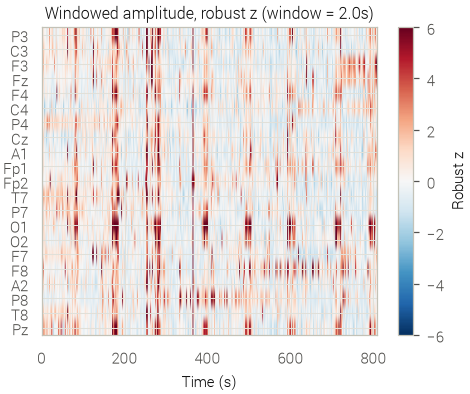

In [10]:
def plot_quality_carpet(raw, win_s=2.0, clip=6):
    raw = raw.copy().pick("eeg")
    X = raw.get_data()
    sf = raw.info["sfreq"]
    n = int(win_s * sf)
    nwin = X.shape[1] // n
    W = X[:, : nwin * n].reshape(len(X), nwin, n)
    amp = W.std(axis=2)

    med = np.median(amp, axis=1, keepdims=True)
    mad = stats.median_abs_deviation(amp, axis=1, scale="normal")[:, None]
    Z = np.clip((amp - med) / np.where(mad == 0, np.nan, mad), -clip, clip)

    fig, ax = plt.subplots(figsize=(COL_W, 2.8))
    im = ax.imshow(Z, aspect="auto", cmap="RdBu_r", vmin=-clip, vmax=clip,
                   extent=[0, nwin * win_s, len(X), 0])
    ax.set_yticks(np.arange(len(X)) + .5)
    ax.set_yticklabels(raw.ch_names)
    ax.set_xlabel("Time (s)")
    ax.set_title(f"Windowed amplitude, robust z (window = {win_s}s)")
    fig.colorbar(im, ax=ax, label="Robust z")
    fig.tight_layout()
    return fig, Z
_ = plot_quality_carpet(raw['subject_30']['session_2']['eeg'])

ICA analysis on the filtered and interpolated signal. eye blink as well as heart beat was identified. The fully preprocessed data wont contain these.

C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\nicol\AppData\Local\Temp\ipykernel_41608\376828301.py:10: RuntimeWarning: The provided ICA instance was fitted with a 'picard' algorithm. ICLabel was designed with extended infomax ICA decompositions. To use the extended infomax algorithm, use the 'mne.preprocessing.ICA' instance with the arguments 'ICA(method='infomax', fit_params=dict(extended=True))' (scikit-learn) or 'ICA(method='picard', fit_params=dict(ortho=False, extended=True))' (python-picard).
  labels = label_components(raw_ica, ica, method="iclabel")


         label      prob
0        other  0.435235
1        other  0.485251
2    eye blink  0.902063
3        brain  0.405408
4   line noise  0.478699
5        brain  0.825459
6        other  0.769021
7    eye blink  0.502458
8        other  0.455423
9   line noise  0.488895
10       other  0.914700
11       other  0.452331
12       brain  0.835764


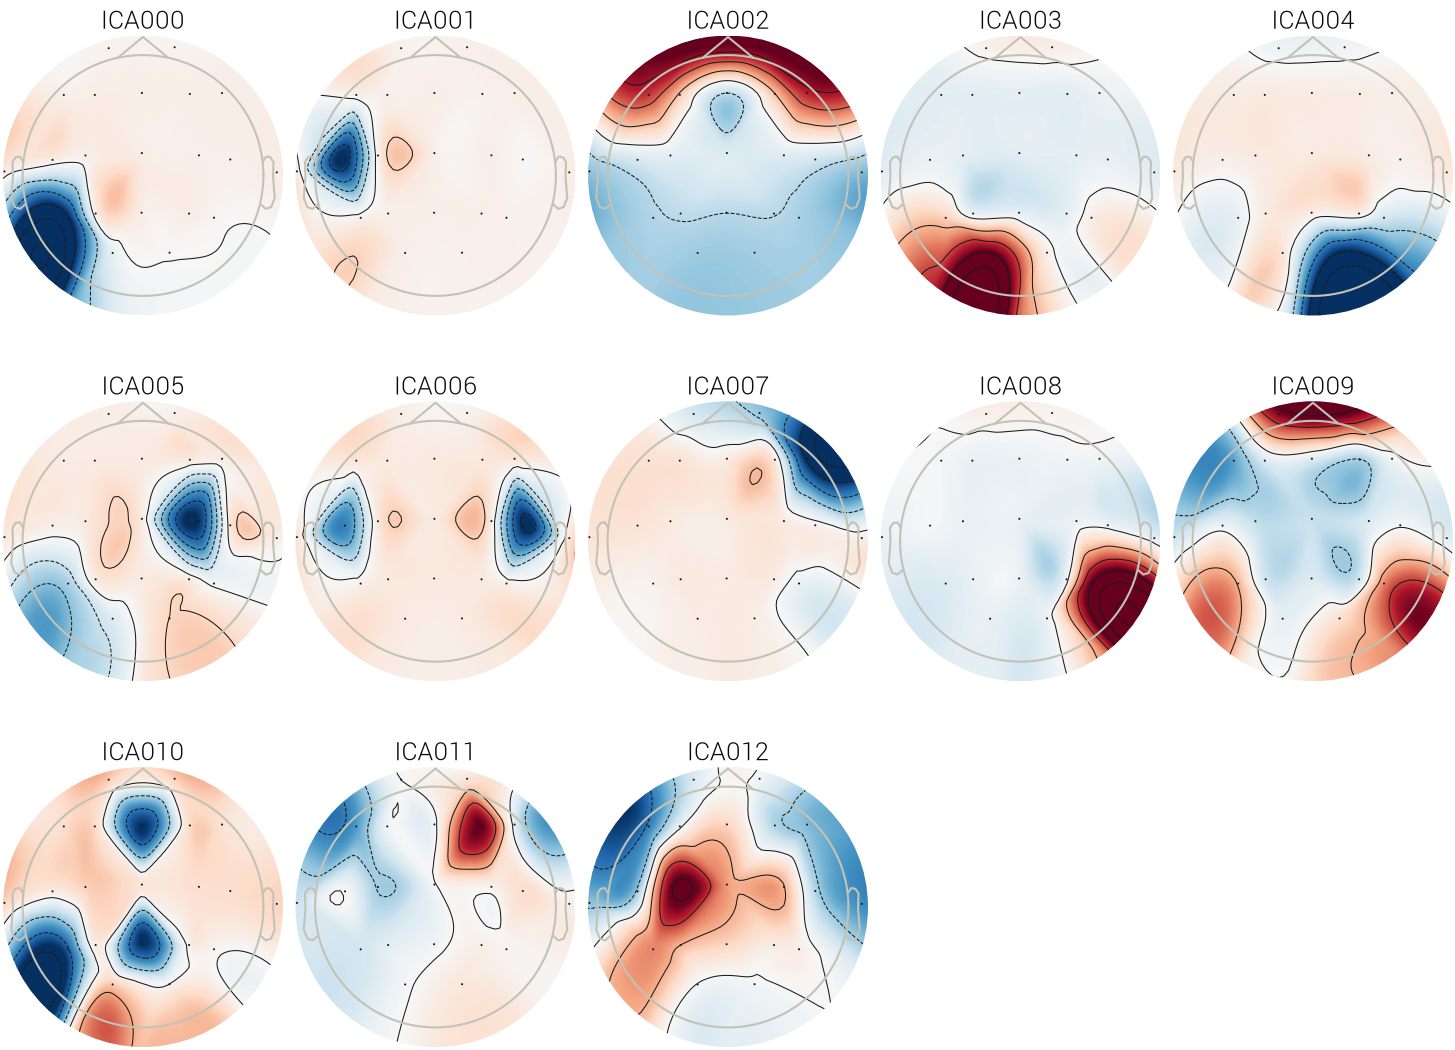

In [11]:
def run_ica_review(raw, n_components=.99, eog_ch=None, method="picard"):
    raw_ica = raw.copy().filter(1., 100., picks="eeg")
    ica = mne.preprocessing.ICA(n_components=n_components, method=method,
                                max_iter="auto", random_state=42)
    ica.fit(raw_ica, picks="eeg")

    labels = None
    try:
        from mne_icalabel import label_components
        labels = label_components(raw_ica, ica, method="iclabel")
        print(pd.DataFrame({"label": labels["labels"],
                            "prob": labels["y_pred_proba"]}))
    except ImportError:
        warnings.warn("mne_icalabel not installed; falling back to EOG correlation")

    figs = ica.plot_components(inst=raw_ica, show=False)
    for fig in (figs if isinstance(figs, list) else [figs]):
        enforce_font_sizes(fig)
    if eog_ch is not None:
        idx, scores = ica.find_bads_eog(raw_ica, ch_name=eog_ch)
        enforce_font_sizes(ica.plot_scores(scores, exclude=idx, show=False))
        print("EOG-correlated components:", idx)
    return ica, labels

_ = run_ica_review(raw['subject_28']['session_1']['eeg_raw'])

# Epoch-Level quality

Epoch quality is assessed by a per-epoch peak-to-peak amplitude. Amplitude distribution should be the same across classes, and also participants.

But we discover that some participants have many epochs with high ptp amplitude values. These are probably bad.

C:\Users\nicol\AppData\Local\Temp\ipykernel_41608\249675823.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=META_COL, y="ptp_uv", order=CLASSES,


Kruskal-Wallis amplitude ~ PinchType: H=34.9, p=1.58e-06   <-- amplitude is class-dependent, be careful


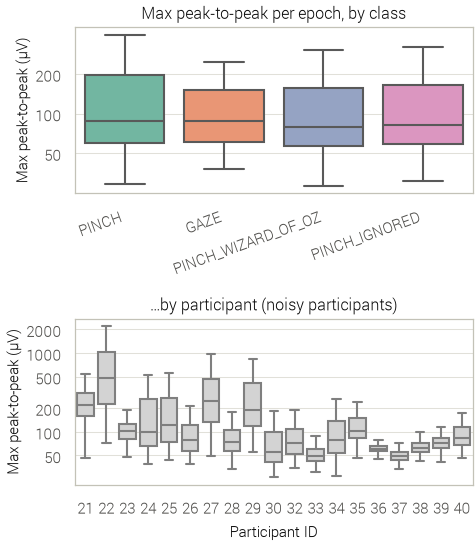

In [12]:
def plot_ptp_by_class(epochs_dict, picks="eeg", figsize=(COL_W, 3.8)):
    rows = []
    for sub, ses, ep in iter_sessions(epochs_dict):
        ep = get_pinchlog(ep).copy().pick(picks)
        X = ep.get_data()
        ptp = (X.max(axis=2) - X.min(axis=2)).max(axis=1) * 1e6  # µV
        rows.append(pd.DataFrame(dict(subject=sub, session=ses,
                                      ptp_uv=ptp,
                                      **{META_COL: ep.metadata[META_COL].values})))
    df = pd.concat(rows, ignore_index=True)
    df["participant"] = df["subject"].map(subject_id)

    fig, axes = plt.subplots(2, 1, figsize=figsize)
    sns.boxplot(data=df, x=META_COL, y="ptp_uv", order=CLASSES,
                palette=PALETTE, showfliers=False, ax=axes[0])
    axes[0].set_yscale("log")
    axes[0].set_title("Max peak-to-peak per epoch, by class")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Max peak-to-peak (µV)")
    plt.setp(axes[0].get_xticklabels(), rotation=20, ha="right")

    sns.boxplot(data=df, x="participant", y="ptp_uv", showfliers=False, ax=axes[1],
                color="lightgray")
    axes[1].set_yscale("log")
    for ax in axes:  # plain 1-2-5 ticks instead of sparse 10^n labels
        ax.yaxis.set_major_locator(mticker.LogLocator(subs=(1, 2, 5)))
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    axes[1].set_title("…by participant (noisy participants)")
    axes[1].set_xlabel("Participant ID")
    axes[1].set_ylabel("Max peak-to-peak (µV)")
    fig.tight_layout()

    groups = [g.ptp_uv.values for _, g in df.groupby(META_COL)]
    H, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis amplitude ~ PinchType: H={H:.1f}, p={p:.3g}"
          + ("   <-- amplitude is class-dependent, be careful" if p < .01 else ""))
    return fig, df

_ = plot_ptp_by_class(epochs_dict)

The rejection is using Autoreject that was introduced by "Autoreject: Automated artifact rejection for MEG and EEG data" (Jas et al. 2017).

The algorithm estimates the optimal peak-to-peak threshold. Bad epochs are then excluded. In the by-subject splitup we see that some subjects have a high rejection rate. This hints to suboptimal measurements. It is probably best to leave out the data of the worst measurements.

AutoReject measures peak-to-peak amplitude, which slow drift inflates. The dataset is highpassed at 0.3Hz, so AutoReject is fitted and takes its drop/interpolate decisions on the same epochs cut from a copy of the continuous `eeg` with an additional 1Hz highpass (`AR_DECISION_L_FREQ`). Those decisions are then applied to the 0.3Hz epochs, which is what `epoch_dataset_filtered` stores.

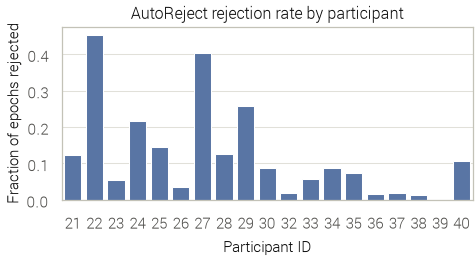

In [13]:
def decision_epochs(ep, raw_eeg, l_freq=AR_DECISION_L_FREQ):
    """The same epochs as `ep` (same event samples, window, baseline, channels, metadata), cut from a
    copy of the continuous signal with an additional `l_freq` highpass. Filtering the continuous
    signal instead of the short epochs avoids filter edge effects."""
    raw_hp = raw_eeg.copy().load_data().filter(l_freq=l_freq, h_freq=None, picks="eeg")
    ep_hp = mne.Epochs(raw_hp, ep.events, event_id=ep.event_id, tmin=ep.tmin, tmax=ep.tmax,
                       baseline=ep.baseline, metadata=ep.metadata, picks=ep.ch_names,
                       reject_by_annotation=False, preload=True, on_missing="ignore")
    assert len(ep_hp) == len(ep) and ep_hp.get_data().shape == ep.get_data().shape
    return ep_hp


def autoreject_report(epochs_dict, raw_dict, n_interpolate=(1, 4, 8), random_state=42):
    """AutoReject per subject/session. Fitting and the drop/interpolate decisions are made on a
    1Hz-highpassed copy (`decision_epochs`), then applied to the 0.3Hz epochs that are returned."""
    from autoreject import AutoReject

    out = []
    cleaned = defaultdict(dict)
    for sub, ses, ep in iter_sessions(epochs_dict):
        ep = get_pinchlog(ep).copy().pick("eeg").load_data()
        ep_decision = decision_epochs(ep, raw_dict[sub][ses]["eeg"])
        ar = AutoReject(n_interpolate=np.array(n_interpolate),
                        random_state=random_state, n_jobs=-1, verbose=False)
        ar.fit(ep_decision)
        log = ar.get_reject_log(ep_decision)                 # decisions on the 1Hz copy ...
        ep_clean = ar.transform(ep, reject_log=log)          # ... applied to the 0.3Hz epochs
        cleaned[sub][ses] = ep_clean
        md = ep.metadata.reset_index(drop=True)
        for cls in CLASSES:
            m = (md[META_COL] == cls).values
            if m.sum() == 0:
                continue
            out.append(dict(subject=sub, session=ses, **{META_COL: cls},
                            n=int(m.sum()),
                            dropped=int(log.bad_epochs[m].sum()),
                            drop_rate=float(log.bad_epochs[m].mean())))
    df = pd.DataFrame(out)

    # Aggregate across sessions/classes to get one drop rate per subject
    sub_df = (df.groupby("subject", as_index=False)[["n", "dropped"]].sum())
    sub_df["drop_rate"] = sub_df["dropped"] / sub_df["n"]
    sub_df["participant"] = sub_df["subject"].map(subject_id)
    sub_order = [subject_id(s) for s in sorted(sub_df["subject"].unique())]

    fig, ax = plt.subplots(figsize=(COL_W, 1.9))
    sns.barplot(data=sub_df, x="participant", y="drop_rate", order=sub_order,
                errorbar=None, ax=ax)
    ax.set(xlabel="Participant ID", ylabel="Fraction of epochs rejected",
           title="AutoReject rejection rate by participant")
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    fig.tight_layout()
    return fig, df, dict(cleaned)

_, drop_df, clean = autoreject_report(epochs_dict, raw)
write_raw_dataset(clean, EPOCH_FILTERED_DATASET_NAME)

## SpecParam

In [14]:
from specparam import SpectralModel
from specparam.plts.spectra import plot_spectra
from specparam.plts.annotate import plot_annotated_model

epochs_clean = merge_epochs_dict(clean)


def query_epochs(epochs, query):
    ep = epochs.copy()
    keep_idx = ep.metadata.query(query).index
    mask = ep.metadata.index.isin(keep_idx)
    return ep[mask]

n_per_seg=1200
epochs_random = query_epochs(epochs_clean, "(EventType == 'NoPinchLog')").copy()
epochs_events = query_epochs(epochs_clean, "((EventType == 'PinchLog') & (PinchType == 'PINCH'))").copy()

spectrum1 = epochs_random.compute_psd(method="welch", fmin=2, fmax=45, n_fft=n_per_seg, n_per_seg=n_per_seg, n_overlap=n_per_seg//2, verbose=False)
psds1 = spectrum1.get_data() * 1e12
freqs1 = spectrum1.freqs

spectrum2 = epochs_events.compute_psd(method="welch", fmin=2, fmax=45, n_fft=n_per_seg, n_per_seg=n_per_seg, n_overlap=n_per_seg//2, verbose=False)
psds2 = spectrum2.get_data() * 1e12
freqs2 = spectrum2.freqs

C:\Users\nicol\AppData\Local\Temp\ipykernel_41608\3372723314.py:74: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  merged = mne.concatenate_epochs(all_epochs)


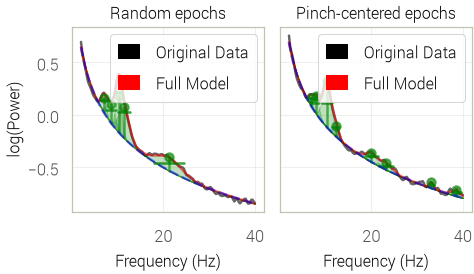

In [15]:
psd1 = psds1[:, 2, :].mean(axis=0)
psd2 = psds2[:, 2, :].mean(axis=0)
#
fm1 = SpectralModel(min_peak_height=0.05, verbose=False)
fm1.fit(freqs1, psd1, (2, 40))
# fm1.plot(plot_peaks='shade', peak_kwargs={'color' : 'green'}, title='Random epochs')
#
fm2 = SpectralModel(min_peak_height=0.05, verbose=False)
fm2.fit(freqs2, psd2, (2, 40))
# fm2.plot(plot_peaks='shade', peak_kwargs={'color' : 'green'}, title='Pinch-centered epochs')

fig, axes = plt.subplots(1, 2, figsize=(COL_W, 2.0), sharey=True, layout='constrained')
plot_annotated_model(fm1, annotate_peaks=False, annotate_aperiodic=False, ax=axes[0])
plot_annotated_model(fm2, annotate_peaks=False, annotate_aperiodic=False, ax=axes[1])
axes[0].set_title('Random epochs')
axes[1].set_title('Pinch-centered epochs')
axes[1].set_ylabel('')
for ax in axes:
    ax.set_xlabel('Frequency (Hz)')
    for line in ax.get_lines():
        line.set_linewidth(min(line.get_linewidth(), 1.2))
        line.set_markersize(min(line.get_markersize(), 4))
enforce_font_sizes(fig, max_size=paper_style.TITLE_FONT)
plt.show()

# Conclusion

Overall measurement quality was suboptimal. The measurements of some subjects are best left out to not poison the remaining measurements, most notably subject 22 and 26.

This conclusion was derrived based on the number of bad electrodes, number of rejected epochs, and PSD characteristics.

## Data Stats

In [5]:
epochs_dict = read_raw_dataset(pathlib.Path('data/epoch_dataset_robust'))

epochs_robust = merge_epochs_dict(epochs_dict)

m = epochs.metadata
# m = epochs_robust.metadata
print(f"Pinch: {m[((m.EventType == 'PinchLog') | (m.EventType == 'NoPinchLog')) & (m.PinchType == 'PINCH')].count().iloc[0]}")
print(f"Gaze: {m[((m.EventType == 'PinchLog') | (m.EventType == 'NoPinchLog')) & (m.PinchType == 'GAZE')].count().iloc[0]}")
print(f"Wizard of oz: {m[((m.EventType == 'PinchLog') | (m.EventType == 'NoPinchLog')) & (m.PinchType == 'PINCH_WIZARD_OF_OZ')].count().iloc[0]}")
print(f"Ignored: {m[((m.EventType == 'PinchLog') | (m.EventType == 'NoPinchLog')) & (m.PinchType == 'PINCH_IGNORED')].count().iloc[0]}")
# print(f"No Pinch: {m[(m.EventType == 'NoPinchLog')].count().loc['EventType']}")
print(f"No Pinch: {m[((m.EventType == 'NoPinchLog')) & (m.PinchType == 'Empty')].count().loc['EventType']}")
print(f"No Pinch Hand Movements: {m[((m.EventType == 'NoPinchLog')) & (m.PinchType == 'FingerMovement')].count().loc['EventType']}")

print(f"Choice: {m[((m.EventType == 'PinchLog')) & (m.isChoiceStimuli) & (m.PinchType=='PINCH')].count().iloc[0]}")
print(f"Delayed feedback: {m[((m.EventType == 'PinchLog')) & (m.feedbackIsDelayed) & (m.PinchType=='PINCH')].count().iloc[0]}")
print(f"Virtual hand: {m[((m.EventType == 'PinchLog')) & (m.hasVirtualHand) & (m.PinchType=='PINCH')].count().iloc[0]}")
print(f"Visual feedback: {m[((m.EventType == 'PinchLog')) & (m.hasVisualFeedback) & (m.PinchType=='PINCH')].count().iloc[0]}")
print(f"Auditory feedback: {m[((m.EventType == 'PinchLog')) & (m.hasAuditoryFeedback) & (m.PinchType=='PINCH')].count().iloc[0]}")

C:\Users\nicol\AppData\Local\Temp\ipykernel_40900\3372723314.py:74: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  merged = mne.concatenate_epochs(all_epochs)


Pinch: 3023
Gaze: 162
Wizard of oz: 681
Ignored: 304
No Pinch: 3242
No Pinch Hand Movements: 182
Choice: 639
Delayed feedback: 353
Virtual hand: 1447
Visual feedback: 2420
Auditory feedback: 2436


In [17]:
m[(m.EventType == 'NoPinchLog')].PinchType.unique()

<ArrowStringArray>
['Empty', 'FingerMovement']
Length: 2, dtype: str